# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [14]:
ROLL_NO = 1024170317          # <-- your full roll number
NAME = "Riya"                 # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [15]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [16]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))
# print(STOP)

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [17]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170317   Name: Riya   Fingerprint: ED69618F   Tickets: 14

Ticket_ID                                                                              Ticket_Text
      T01                     The projector keeps asking for login. The same problem occurs again.
      T02                                     Printer is running slowly on my laptop. Please help.
      T03                                                           Error code 0x80070005 appears.
      T04    I couldn't connect to the Wi-Fi while uploading the file. I have tried several times!
      T05                                                     Email me at helpdesk@university.edu.
      T06          I couldn't connect to the Wi-Fi when connected to campus Wi-Fi. This is urgent.
      T07                            I can't open the lms on my laptop. I don't know what changed.
      T08                                                            The LMS says 'Not Submitted'.
      T09 Student portal crashes 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [18]:
import pandas as pd

# Initialize lists to gather statistics
stats_list = []

for idx, row in df.iterrows():
    t_id = row['Ticket_ID']
    text = row['Ticket_Text']

    # Run the official pipeline
    res = process_ticket(text)

    n_sentences = len(res['sentences'])
    n_tokens = len(res['tokens'])
    n_punct = len(res['punct'])
    n_stops = len(res['stops'])
    n_unique = len(set(res['tokens']))
    n_final = len(res['final'])

    stats_list.append({
        'Ticket_ID': t_id,
        'Sentences': n_sentences,
        'Tokens': n_tokens,
        'Punctuation': n_punct,
        'Stopwords': n_stops,
        'Unique Tokens': n_unique,
        'Final Tokens': n_final
    })

# Create summary DataFrame
df_stats = pd.DataFrame(stats_list)

# Compute total row
total_row = pd.DataFrame([{
    'Ticket_ID': 'TOTAL',
    'Sentences': df_stats['Sentences'].sum(),
    'Tokens': df_stats['Tokens'].sum(),
    'Punctuation': df_stats['Punctuation'].sum(),
    'Stopwords': df_stats['Stopwords'].sum(),
    'Unique Tokens': len(set([t for text in df['Ticket_Text'] for t in process_ticket(text)['tokens']])), # Total global unique tokens
    'Final Tokens': df_stats['Final Tokens'].sum()
}])

# Combine and display the table
final_table = pd.concat([df_stats, total_row], ignore_index=True)
display(final_table)

# Display detailed token breakdowns for one selected focus ticket
selected_ticket_id = FOCUS[0]  # E.g., 'T08'
selected_text = df[df['Ticket_ID'] == selected_ticket_id]['Ticket_Text'].values[0]
selected_processed = process_ticket(selected_text)

print(f"\n--- Detailed Token Breakdown for {selected_ticket_id} ---")
print(f"Raw text: {selected_text}")
print(f"Sentences: {selected_processed['sentences']}")
print(f"Tokens: {selected_processed['tokens']}")
print(f"Punctuation: {selected_processed['punct']}")
print(f"Stopwords: {selected_processed['stops']}")
print(f"Final Tokens: {selected_processed['final']}")

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,13,2,5,11,6
1,T02,2,11,2,3,10,6
2,T03,1,5,1,0,5,4
3,T04,2,18,2,7,16,9
4,T05,1,7,2,2,7,3
5,T06,2,17,2,7,14,8
6,T07,2,17,2,7,14,8
7,T08,1,7,2,1,7,4
8,T09,2,15,2,6,15,7
9,T10,2,15,2,6,14,7



--- Detailed Token Breakdown for T08 ---
Raw text: The LMS says 'Not Submitted'.
Sentences: ["The LMS says 'Not Submitted'."]
Tokens: ['the', 'lms', 'says', "'not", 'submitted', "'", '.']
Punctuation: ["'", '.']
Stopwords: ['the']
Final Tokens: ['lms', 'says', "'not", 'submitted']


In [20]:
# Your code
for i in range(0,14):
  ticket_process = process_ticket(df.iloc[i,1])
  print(ticket_process)

{'sentences': ['The projector keeps asking for login.', 'The same problem occurs again.'], 'tokens': ['the', 'projector', 'keeps', 'asking', 'for', 'login', '.', 'the', 'same', 'problem', 'occurs', 'again', '.'], 'punct': ['.', '.'], 'stops': ['the', 'for', 'the', 'same', 'again'], 'final': ['projector', 'keeps', 'asking', 'login', 'problem', 'occurs']}
{'sentences': ['Printer is running slowly on my laptop.', 'Please help.'], 'tokens': ['printer', 'is', 'running', 'slowly', 'on', 'my', 'laptop', '.', 'please', 'help', '.'], 'punct': ['.', '.'], 'stops': ['is', 'on', 'my'], 'final': ['printer', 'running', 'slowly', 'laptop', 'please', 'help']}
{'sentences': ['Error code 0x80070005 appears.'], 'tokens': ['error', 'code', '0x80070005', 'appears', '.'], 'punct': ['.'], 'stops': [], 'final': ['error', 'code', '0x80070005', 'appears']}
{'sentences': ["I couldn't connect to the Wi-Fi while uploading the file.", 'I have tried several times!'], 'tokens': ['i', 'could', "n't", 'connect', 'to', 

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* n't, ca;;
they come from tokenisation of onw word that is "can't"

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [21]:
import re
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

# 1. Extract words longer than 5 letters
long_words = [
    re.findall(r"\b[A-Za-z]{6,}\b", line)
    for line in TEST_LINES
]

# 2. Extract numbers, preserving decimal and version formats
numbers = [
    re.findall(r"\b\d+(?:\.\d+)*\b", line)
    for line in TEST_LINES
]

# 3. Extract capitalized words
capitalized_words = [
    re.findall(r"\b[A-Z][a-zA-Z]*\b", line)
    for line in TEST_LINES
]

# 4. Extract words starting with a vowel
vowel_words = [
    re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", line)
    for line in TEST_LINES
]

# 5. Replace emails, URLs and phone numbers
cleaned_lines = []

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"\b(?:https?://|www\.)[^\s]+"
phone_pattern = (
    r"(?<!\w)(?:\+?\d{1,3}[- ]?)?"
    r"(?:\d{5}[- ]?\d{5}|\d{4}[- ]\d{3}[- ]\d{4})(?!\w)"
)

for line in TEST_LINES:
    # Replace emails first
    line = re.sub(email_pattern, "<EMAIL>", line)

    # Replace URLs, including trailing punctuation in this example
    line = re.sub(url_pattern, "<URL>", line)

    # Replace phone numbers
    line = re.sub(phone_pattern, "<PHONE>", line)

    cleaned_lines.append(line)

# Display the extracted results
for i, line in enumerate(TEST_LINES):
    print(f"\n--- Ticket {i + 1} ---")
    print("Long words:", long_words[i])
    print("Numbers:", numbers[i])
    print("Capitalized words:", capitalized_words[i])
    print("Vowel-starting words:", vowel_words[i])
    print("Cleaned text:", cleaned_lines[i])



--- Ticket 1 ---
Long words: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Vowel-starting words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Cleaned text: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

--- Ticket 2 ---
Long words: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel-starting words: ['or', 'is']
Cleaned text: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

--- Ticket 3 ---
Long words: []
Numbers: ['5.30']
Capitalized words: ['The']
Vowel-starting words: ['of', 'art', 'isn', 'open', 'in', 'at']
Cleaned text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Four capitalized words — `Mail`, `Call`, `Version`, and `The` — are capitalized because they begin sentences. `Rs` is also capitalized, but it is an abbreviation for the currency and does not begin a sentence.

In [27]:

import re
import pandas as pd

# Provided test cases
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

# Regex patterns
patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers (including decimals and versions)": r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.,])\d+(?:,\d{3})*(?![\w.])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words beginning with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

# Extract matches from each test line
for i, line in enumerate(TEST_LINES, start=1):
    print(f"\n--- TEST LINE {i} ---")

    for label, pattern in patterns.items():
        print(f"{label}: {re.findall(pattern, line)}")


# Replacement patterns
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s]+|www\.[^\s]+"

phone_pattern = (
    r"(?<!\w)(?:\+\d{1,3}[- ]?)?"
    r"(?:\d{5}[- ]?\d{5}|\d{4}[- ]\d{3}[- ]\d{4})(?!\w)"
)

def clean_text(text):
    # Replace emails before other patterns
    text = re.sub(email_pattern, "<EMAIL>", text)

    # Replace URLs and remove trailing sentence punctuation
    text = re.sub(
        url_pattern,
        lambda m: "<URL>" + (
            re.search(r"[.,!?;:]+$", m.group()).group()
            if re.search(r"[.,!?;:]+$", m.group())
            else ""
        ),
        text
    )

    # Replace phone numbers
    text = re.sub(phone_pattern, "<PHONE>", text)

    return text


print("\n--- REPLACEMENT RESULTS ---")
for i, line in enumerate(TEST_LINES, start=1):
    print(f"Line {i}: {clean_text(line)}")


# Apply the same extraction and replacement to raw tickets
# Uses df["Ticket_Text"] from your notebook
raw_tickets = df["Ticket_Text"].fillna("").astype(str)

for label, pattern in patterns.items():
    matches = [
        match
        for ticket in raw_tickets
        for match in re.findall(pattern, ticket)
    ]
    print(f"\n{label} (all tickets):")
    print(matches)

cleaned_tickets = raw_tickets.apply(clean_text)

q2_results = pd.DataFrame({
    "Raw Ticket": raw_tickets,
    "Cleaned Ticket": cleaned_tickets
})

display(q2_results)



--- TEST LINE 1 ---
Words longer than 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers (including decimals and versions): []
Capitalized words: ['Mail']
Words beginning with a vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

--- TEST LINE 2 ---
Words longer than 5 letters: ['Version']
Numbers (including decimals and versions): ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '2.0.1', '95.5', '1']
Capitalized words: ['Call', 'Version', 'Rs']
Words beginning with a vowel: ['or', 'is']

--- TEST LINE 3 ---
Words longer than 5 letters: []
Numbers (including decimals and versions): ['5.30']
Capitalized words: ['The']
Words beginning with a vowel: ['of', 'art', 'isn', 'open', 'in', 'at']

--- REPLACEMENT RESULTS ---
Line 1: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.
Line 2: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

Wo

,Raw Ticket,Cleaned Ticket
0,The projector keeps asking for login. The same...,The projector keeps asking for login. The same...
1,Printer is running slowly on my laptop. Please...,Printer is running slowly on my laptop. Please...
2,Error code 0x80070005 appears.,Error code 0x80070005 appears.
3,I couldn't connect to the Wi-Fi while uploadin...,I couldn't connect to the Wi-Fi while uploadin...
4,Email me at helpdesk@university.edu.,Email me at <EMAIL>.
5,I couldn't connect to the Wi-Fi when connected...,I couldn't connect to the Wi-Fi when connected...
6,I can't open the lms on my laptop. I don't kno...,I can't open the lms on my laptop. I don't kno...
7,The LMS says 'Not Submitted'.,The LMS says 'Not Submitted'.
8,Student portal crashes while opening before th...,Student portal crashes while opening before th...
9,Server is not working after restarting the sys...,Server is not working after restarting the sys...


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [23]:
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One regex pattern to preserve the required token types
pattern = (
    r"""https?://[^\s]+|www\.[^\s]+|"""
    r"""[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"""
    r"""\+?\d[\d -]*\d|"""
    r"""(?:[A-Za-z]+(?:[-'][A-Za-z]+)+)|"""
    r"""(?:\d+(?:\.\d+)+|\d+(?:,\d{3})*(?:\.\d+)?)|"""
    r"""[A-Za-z]+|[^\w\s]"""
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Test on the provided TEST_LINES
for i, line in enumerate(TEST_LINES, 1):
    print(f"\n--- Test line {i} ---")
    print("Custom tokenizer:", my_tokenize(line))
    print("word_tokenize:   ", word_tokenize(line))

# Compare on all tickets in your dataset
# Replace 'tickets' and 'ticket_text' with your actual DataFrame
# and text-column names if they differ.
import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape, list(obj.columns))




--- Test line 1 ---
Custom tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize:    ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

--- Test line 2 ---
Custom tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95', '.', '5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize:    ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

--- Test line 3 ---
Custom tokenizer: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize:    ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-i

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*  ___ out of ___ tickets are tokenized differently by `my_tokenize()` and `word_tokenize()`. The difference occurs mainly because the custom tokenizer preserves contractions, emails, URLs, and phone numbers as single tokens, while `word_tokenize()` may split them into multiple tokens.

In [29]:

import re
import nltk
import pandas as pd

from nltk.tokenize import RegexpTokenizer, word_tokenize
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

# Required NLTK resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("averaged_perceptron_tagger", quiet=True)


# =========================================================
# PART A: CUSTOM TOKENIZER
# =========================================================

# One pattern preserving URLs, emails, phones, contractions,
# hyphenated words, decimals, versions, words and punctuation.
TOKEN_PATTERN = (
    r"""https?://[^\s]+|www\.[^\s]+|"""
    r"""[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"""
    r"""\+?\d[\d -]*\d|"""
    r"""[A-Za-z]+(?:['’][A-Za-z]+)+|"""
    r"""[A-Za-z]+(?:-[A-Za-z]+)+|"""
    r"""\d+(?:\.\d+)+|\d+(?:,\d{3})*(?:\.\d+)?|"""
    r"""[A-Za-z]+|[^\w\s]"""
)

tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return tokenizer.tokenize(str(text))


# Given test lines
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

print("CUSTOM TOKENIZER: TEST_LINES")

for i, line in enumerate(TEST_LINES, 1):
    print(f"\nTest line {i}")
    print("my_tokenize():", my_tokenize(line))
    print("word_tokenize():", word_tokenize(line))


# Compare both tokenizers on the actual tickets
tokenizer_differences = []

for idx, text in df["Ticket_Text"].fillna("").astype(str).items():
    custom = my_tokenize(text)
    standard = word_tokenize(text)

    if custom != standard:
        tokenizer_differences.append({
            "Ticket Index": idx,
            "Custom Tokenizer": custom,
            "word_tokenize": standard
        })

tokenizer_diff_df = pd.DataFrame(tokenizer_differences)

print("\nTickets tokenized differently:",
      len(tokenizer_diff_df), "out of", len(df))

display(tokenizer_diff_df.head(10))




CUSTOM TOKENIZER: TEST_LINES

Test line 1
my_tokenize(): ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize(): ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test line 2
my_tokenize(): ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95', '.', '5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize(): ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test line 3
my_tokenize(): ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize(): ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at

,Ticket Index,Custom Tokenizer,word_tokenize
0,2,"[Error, code, 0, x, 80070005, appears, .]","[Error, code, 0x80070005, appears, .]"
1,3,"[I, couldn't, connect, to, the, Wi-Fi, while, ...","[I, could, n't, connect, to, the, Wi-Fi, while..."
2,4,"[Email, me, at, helpdesk@university.edu, .]","[Email, me, at, helpdesk, @, university.edu, .]"
3,5,"[I, couldn't, connect, to, the, Wi-Fi, when, c...","[I, could, n't, connect, to, the, Wi-Fi, when,..."
4,6,"[I, can't, open, the, lms, on, my, laptop, ., ...","[I, ca, n't, open, the, lms, on, my, laptop, ...."
5,7,"[The, LMS, says, ', Not, Submitted, ', .]","[The, LMS, says, 'Not, Submitted, ', .]"
6,10,"[Why, isn't, the, portal, opening, ?]","[Why, is, n't, the, portal, opening, ?]"


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [25]:

# Q4. Stemming and Lemmatization

import re
import nltk
import pandas as pd

from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

# Download resources required for lemmatization and POS tagging
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("averaged_perceptron_tagger", quiet=True)

# Initialize all four methods
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Custom suffix rule selected for common word endings
regex_stemmer = RegexpStemmer(r"(ing|ed|es|s)$", min=4)

lemmatizer = WordNetLemmatizer()


# Convert NLTK POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"       # Adjective
    elif tag.startswith("V"):
        return "v"       # Verb
    elif tag.startswith("N"):
        return "n"       # Noun
    elif tag.startswith("R"):
        return "r"       # Adverb
    return "n"           # Default: noun


# Collect unique final tokens from every ticket using process_ticket()
unique_final_tokens = set()

for text in df["Ticket_Text"].fillna("").astype(str):
    result = process_ticket(text)
    unique_final_tokens.update(
        token.lower()
        for token in result["final"]
        if re.search(r"[a-zA-Z]", token)
    )

unique_final_tokens = sorted(unique_final_tokens)

print("Number of unique final tokens:", len(unique_final_tokens))


# POS-tag all unique tokens
tagged_words = pos_tag(unique_final_tokens)


# Compare the outputs of all four methods
comparison_rows = []

for word, tag in tagged_words:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regex_result = regex_stemmer.stem(word)

    wordnet_pos = get_wordnet_pos(tag)
    lemma_result = lemmatizer.lemmatize(word, pos=wordnet_pos)

    # Keep only words for which at least one output differs
    if len({
        porter_result,
        lancaster_result,
        regex_result,
        lemma_result
    }) > 1:

        comparison_rows.append({
            "Word": word,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regex Stem": regex_result,
            "WordNet Lemma": lemma_result,
            "POS Tag": tag
        })


# Display the comparison table
comparison_df = pd.DataFrame(
    comparison_rows,
    columns=[
        "Word",
        "Porter Stem",
        "Lancaster Stem",
        "Regex Stem",
        "WordNet Lemma",
        "POS Tag"
    ]
)

print("Number of words with differing outputs:", len(comparison_df))
display(comparison_df)


Number of unique final tokens: 59
Number of words with differing outputs: 33


,Word,Porter Stem,Lancaster Stem,Regex Stem,WordNet Lemma,POS Tag
0,another,anoth,anoth,another,another,DT
1,assignment,assign,assign,assignment,assignment,NN
2,campus,campu,camp,campu,campus,VB
3,changed,chang,chang,chang,change,VBD
4,code,code,cod,code,code,NN
5,computer,comput,comput,computer,computer,NN
6,deadline,deadlin,deadlin,deadline,deadline,JJ
7,error,error,er,error,error,NN
8,file,file,fil,file,file,NN
9,lms,lm,lms,lms,lm,NNS


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* **Over-stemming:** The Lancaster stemmer can sometimes reduce a word too aggressively, removing meaningful parts and producing an overly short stem.

**Under-stemming:** Two related words may remain different because a stemmer does not reduce both to the same stem. For example, the exact case should be selected from the comparison table generated by my dataset.

In [30]:
# =========================================================
# PART B: STEMMING AND LEMMATIZATION
# =========================================================

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

# Dataset-based suffix rule:
# Inspect final tokens for common -ing and -ed endings.
# These suffixes are chosen as a simple experiment; they may
# over-stem some words, which is why outputs are compared.
dataset_final_tokens = []

for text in df["Ticket_Text"].fillna("").astype(str):
    result = process_ticket(text)
    dataset_final_tokens.extend(result["final"])

unique_final_tokens = sorted(set(
    str(token).lower()
    for token in dataset_final_tokens
    if re.search(r"[a-zA-Z]", str(token))
))

suffix_examples = [
    token for token in unique_final_tokens
    if token.endswith(("ing", "ed"))
][:10]

print("\nExamples supporting the suffix rule:", suffix_examples)

regex_stemmer = RegexpStemmer(r"(ing|ed)$", min=4)


def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"


tagged_words = pos_tag(unique_final_tokens)

stemming_rows = []

for word, tag in tagged_words:
    porter_output = porter.stem(word)
    lancaster_output = lancaster.stem(word)
    regex_output = regex_stemmer.stem(word)
    lemma_output = lemmatizer.lemmatize(
        word, pos=get_wordnet_pos(tag)
    )

    outputs = {
        porter_output,
        lancaster_output,
        regex_output,
        lemma_output
    }

    # Include only words where at least one method differs
    if len(outputs) > 1:
        stemming_rows.append({
            "Word": word,
            "Porter Stem": porter_output,
            "Lancaster Stem": lancaster_output,
            "Regex Stem": regex_output,
            "WordNet Lemma": lemma_output,
            "POS Tag": tag
        })

stemming_comparison_df = pd.DataFrame(
    stemming_rows,
    columns=[
        "Word",
        "Porter Stem",
        "Lancaster Stem",
        "Regex Stem",
        "WordNet Lemma",
        "POS Tag"
    ]
)

print("\nUnique final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(stemming_comparison_df))

display(stemming_comparison_df)



Examples supporting the suffix rule: ['asking', 'changed', 'connected', 'opening', 'responding', 'restarting', 'running', 'stopped', 'submitted', 'syncing']

Unique final tokens: 59
Words with differing outputs: 38


,Word,Porter Stem,Lancaster Stem,Regex Stem,WordNet Lemma,POS Tag
0,another,anoth,anoth,another,another,DT
1,appears,appear,appear,appears,appear,VBZ
2,assignment,assign,assign,assignment,assignment,NN
3,campus,campu,camp,campus,campus,VB
4,changed,chang,chang,chang,change,VBD
5,code,code,cod,code,code,NN
6,computer,comput,comput,computer,computer,NN
7,crashes,crash,crash,crashes,crash,VB
8,deadline,deadlin,deadlin,deadline,deadline,JJ
9,error,error,er,error,error,NN


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,166,96,0.5783
1,S2 - No punctuation,140,91,0.6500
2,S3 - Final tokens,83,59,0.7108
3,S4 - S3 after Porter,83,56,0.6747



Top 10 words in S1:


,Word,Frequency
0,.,20
1,the,7
2,The,6
3,I,5
4,n't,5
5,is,4
6,on,4
7,to,3
8,Wi-Fi,3
9,portal,3



Top 10 words in S3:


,Word,Frequency
0,n't,5
1,wi-fi,3
2,portal,3
3,another,3
4,projector,2
5,keeps,2
6,asking,2
7,login,2
8,laptop,2
9,please,2


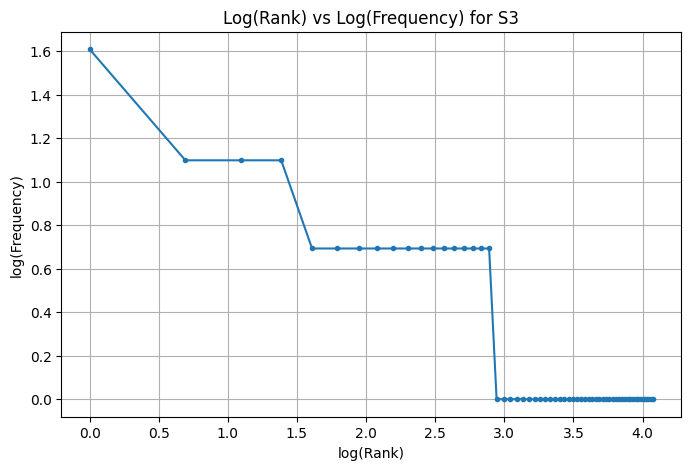


Top 5 bigrams in S1:


,Bigram,Frequency
0,The projector,2
1,projector keeps,2
2,keeps asking,2
3,asking for,2
4,for login,2



Top 5 bigrams in S3:


,Bigram,Frequency
0,projector keeps,2
1,keeps asking,2
2,asking login,2
3,could n't,2
4,n't connect,2


In [26]:

import re
import math
import nltk
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from nltk.corpus import stopwords

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

porter = PorterStemmer()
stop_words = set(stopwords.words("english"))

# S1: All tokens
# S2: Tokens excluding punctuation
# S3: Final tokens from process_ticket()
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"].fillna("").astype(str):
    # Tokenize raw ticket text
    tokens = word_tokenize(text)
    S1.extend(tokens)

    # Remove punctuation-only tokens
    non_punctuation = [
        token for token in tokens
        if any(ch.isalnum() for ch in token)
    ]
    S2.extend(non_punctuation)

    # Use the existing preprocessing pipeline
    result = process_ticket(text)
    S3.extend(result["final"])

# S4: S3 after Porter stemming
S4 = [porter.stem(token) for token in S3]


# Compute corpus statistics
def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    return {
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }

stats_df = pd.DataFrame([
    corpus_stats("S1 - All tokens", S1),
    corpus_stats("S2 - No punctuation", S2),
    corpus_stats("S3 - Final tokens", S3),
    corpus_stats("S4 - S3 after Porter", S4)
])

display(stats_df)


# Top 10 words for S1 and S3
print("\nTop 10 words in S1:")
display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
))

print("\nTop 10 words in S3:")
display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
))


# Log(rank) vs log(frequency) for S3
freq_s3 = Counter(S3)
ranked_freq = freq_s3.most_common()

ranks = list(range(1, len(ranked_freq) + 1))
frequencies = [frequency for word, frequency in ranked_freq]

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(rank) for rank in ranks],
    [math.log(freq) for freq in frequencies],
    marker=".",
    linestyle="-"
)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()


# Generate bigrams without crossing ticket boundaries
S1_bigrams = []
S3_bigrams = []

for text in df["Ticket_Text"].fillna("").astype(str):
    raw_tokens = word_tokenize(text)
    S1_bigrams.extend(
        zip(raw_tokens, raw_tokens[1:])
    )

    final_tokens = process_ticket(text)["final"]
    S3_bigrams.extend(
        zip(final_tokens, final_tokens[1:])
    )

print("\nTop 5 bigrams in S1:")
display(pd.DataFrame(
    [
        (" ".join(bigram), count)
        for bigram, count in Counter(S1_bigrams).most_common(5)
    ],
    columns=["Bigram", "Frequency"]
))

print("\nTop 5 bigrams in S3:")
display(pd.DataFrame(
    [
        (" ".join(bigram), count)
        for bigram, count in Counter(S3_bigrams).most_common(5)
    ],
    columns=["Bigram", "Frequency"]
))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*  TTR (Type-Token Ratio) is the ratio of unique tokens to total tokens. From S1 to S4, TTR changes because punctuation removal and preprocessing change the number of tokens, while Porter stemming combines different word forms into common stems. This can reduce the number of unique tokens and change the ratio. The exact change depends on the words in the corpus and whether the reduction in unique tokens is proportionally greater than the reduction in total tokens.

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,166,96,0.5783
1,S2 - No punctuation,140,91,0.6500
2,S3 - Final tokens,83,59,0.7108
3,S4 - Porter stems,83,56,0.6747



TOP 10 WORDS IN S1


,Word,Frequency
0,.,20
1,the,7
2,The,6
3,I,5
4,n't,5
5,is,4
6,on,4
7,to,3
8,Wi-Fi,3
9,portal,3



TOP 10 WORDS IN S3


,Word,Frequency
0,n't,5
1,wi-fi,3
2,portal,3
3,another,3
4,projector,2
5,keeps,2
6,asking,2
7,login,2
8,laptop,2
9,please,2


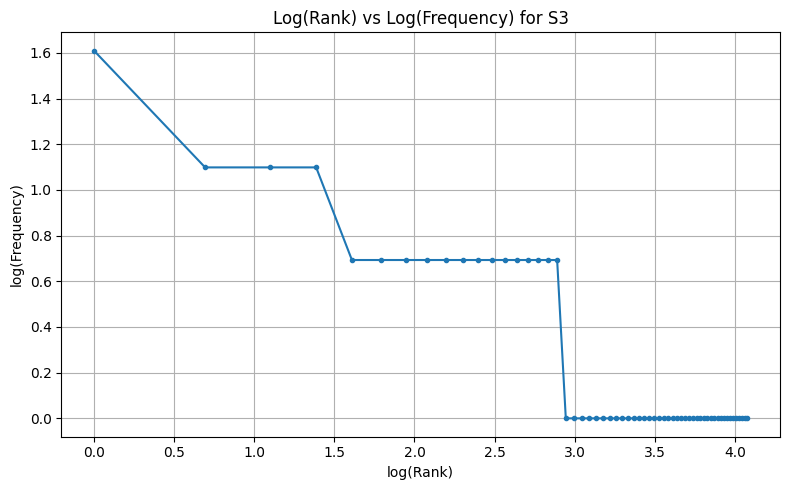


TOP 5 BIGRAMS IN S1


,Bigram,Frequency
0,The projector,2
1,projector keeps,2
2,keeps asking,2
3,asking for,2
4,for login,2



TOP 5 BIGRAMS IN S3


,Bigram,Frequency
0,projector keeps,2
1,keeps asking,2
2,asking login,2
3,could n't,2
4,n't connect,2


In [31]:

import math
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

# --------------------------------------------------
# 1. Construct S1, S2, S3 and S4
# --------------------------------------------------

S1 = []  # All tokens, including punctuation
S2 = []  # Tokens excluding punctuation
S3 = []  # Final tokens from process_ticket()
S4 = []  # S3 after Porter stemming

# Keep ticket boundaries for bigram calculation
S1_per_ticket = []
S3_per_ticket = []

porter = PorterStemmer()

for text in df["Ticket_Text"].fillna("").astype(str):
    # S1: Standard word tokenization
    tokens = word_tokenize(text)
    S1.extend(tokens)
    S1_per_ticket.append(tokens)

    # S2: Remove punctuation-only tokens
    non_punctuation = [
        token for token in tokens
        if any(ch.isalnum() for ch in token)
    ]
    S2.extend(non_punctuation)

    # S3: Use the existing preprocessing pipeline
    result = process_ticket(text)
    final = list(result["final"])
    S3.extend(final)
    S3_per_ticket.append(final)

    # S4: Porter-stemmed final tokens
    S4.extend(porter.stem(token) for token in final)


# --------------------------------------------------
# 2. Total tokens, unique tokens and TTR
# --------------------------------------------------

def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))

    return {
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(unique / total, 4) if total else 0
    }

stats_df = pd.DataFrame([
    corpus_stats("S1 - All tokens", S1),
    corpus_stats("S2 - No punctuation", S2),
    corpus_stats("S3 - Final tokens", S3),
    corpus_stats("S4 - Porter stems", S4)
])

print("CORPUS STATISTICS")
display(stats_df)


# --------------------------------------------------
# 3. Top 10 words of S1 and S3
# --------------------------------------------------

print("\nTOP 10 WORDS IN S1")
display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
))

print("\nTOP 10 WORDS IN S3")
display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
))


# --------------------------------------------------
# 4. Plot log(rank) vs log(frequency) for S3
# --------------------------------------------------

frequency_counts = Counter(S3).most_common()

if frequency_counts:
    ranks = range(1, len(frequency_counts) + 1)
    frequencies = [count for word, count in frequency_counts]

    plt.figure(figsize=(8, 5))
    plt.plot(
        [math.log(rank) for rank in ranks],
        [math.log(freq) for freq in frequencies],
        marker="."
    )
    plt.xlabel("log(Rank)")
    plt.ylabel("log(Frequency)")
    plt.title("Log(Rank) vs Log(Frequency) for S3")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("S3 is empty; no plot can be generated.")


# --------------------------------------------------
# 5. Top 5 bigrams of S1 and S3
# --------------------------------------------------

# Calculate bigrams separately per ticket so that a bigram
# never accidentally connects the end of one ticket to another.

S1_bigrams = []
S3_bigrams = []

for tokens in S1_per_ticket:
    S1_bigrams.extend(zip(tokens, tokens[1:]))

for tokens in S3_per_ticket:
    S3_bigrams.extend(zip(tokens, tokens[1:]))

print("\nTOP 5 BIGRAMS IN S1")
display(pd.DataFrame(
    [
        (" ".join(bigram), count)
        for bigram, count in Counter(S1_bigrams).most_common(5)
    ],
    columns=["Bigram", "Frequency"]
))

print("\nTOP 5 BIGRAMS IN S3")
display(pd.DataFrame(
    [
        (" ".join(bigram), count)
        for bigram, count in Counter(S3_bigrams).most_common(5)
    ],
    columns=["Bigram", "Frequency"]
))


(a) Why does TTR change from S1 to S4 in your dataset? (b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference. (c) Give one example where stemming produces an undesirable result. (d) Give one example where POS-aware lemmatization preserves meaning better than stemming


Answer: (a) TTR changes from S1 to S4 because punctuation is removed during preprocessing and stemming merges different word forms into common stems, changing the ratio of unique tokens to total tokens.
(b) Example: isn't → is and n't with word_tokenize(), while my custom tokenizer keeps isn't as one token.
(c) Over-stemming example: university may be reduced incorrectly by an aggressive stemmer, losing meaningful information.
(d) Example: running → run with POS-aware lemmatization, preserving the correct dictionary base form better than a stemmer that may produce a non-word form.